# RegimeShift — HMM-driven multi-asset regime rotation

This notebook walks through the same pipeline as `scripts/run_backtest.py`,
importing everything from `src/` (no duplicated logic), with narrative and
inline plots.

**The idea.** Markets spend long stretches in persistent *regimes* — calm
uptrends, choppy sideways markets, high-volatility crises — and the optimal
portfolio differs sharply between them. A Hidden Markov Model is a natural fit:
it assumes an unobserved discrete state (the regime) that evolves with some
persistence, and that observable features (returns, volatility) are drawn from
state-dependent distributions. We detect the state *causally* — using only data
available at each decision date — and rotate a NIFTY 50 / gold / cash-bond
portfolio accordingly, then compare against 60/40 and equal-weight benchmarks
under identical transaction costs.

**The one rule that matters: no lookahead.** Every quantity used at decision
date `t` (features, feature scaling, HMM parameters, regime label, expected
returns, covariances) is computed from data up to and including `t` and nothing
after. The two classic traps are avoided explicitly:

1. `hmm.predict()` / `predict_proba()` decode each date using the **entire**
   sequence — including the future. We use the **filtered** (forward-pass only)
   posterior instead (`src/regime.py`).
2. Feature scalers and moment estimates are fit on trailing/training windows
   only (`src/features.py`, `src/optimize.py`).

`tests/test_no_lookahead.py` enforces this mechanically: truncating or
perturbing future data must leave all earlier signals byte-for-byte unchanged.

In [1]:
import sys, logging, warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # notebook lives in notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
logging.basicConfig(level=logging.INFO, format="%(levelname)s %(message)s")

from src.config import BACKTEST_CONFIG, RESULTS_DIR
from src.data import load_prices, chosen_tickers
from src.features import build_features
from src.regime import fit_hmm, filtered_posteriors, filtered_labels
from src.backtest import run_walkforward
from src.benchmarks import run_benchmarks
from src.metrics import stats_table, regime_stats, save_all_plots

## 1. Data

Three INR-denominated assets (single currency, so regime signals aren't
contaminated by USDINR): NIFTY 50, an INR gold ETF, and a cash-like liquid ETF
as the defensive leg (Yahoo's gilt-ETF histories only start 2016+, which would
cost seven years of history — see the README data notes). Prices are cached in
`data/cache/`; pass `refresh=True` to force a re-download.

In [2]:
print(chosen_tickers())
prices=load_prices()
prices.tail(3)

INFO equity -> ^NSEI (4609 rows, 2007-09-17 to 2026-07-03)


INFO gold -> GOLDBEES.NS (4314 rows, 2009-01-02 to 2026-07-03)


WARNING GOLDBEES.NS: replaced 2 bad print(s)


INFO bonds -> LIQUIDBEES.NS (4315 rows, 2009-01-02 to 2026-07-03)


INFO equity -> ^NSEI (4609 rows, 2007-09-17 to 2026-07-03)


INFO gold -> GOLDBEES.NS (4314 rows, 2009-01-02 to 2026-07-03)


WARNING GOLDBEES.NS: replaced 2 bad print(s)


INFO bonds -> LIQUIDBEES.NS (4315 rows, 2009-01-02 to 2026-07-03)


INFO aligned panel: 4316 days, 2009-01-02 to 2026-07-03


{'equity': '^NSEI', 'gold': 'GOLDBEES.NS', 'bonds': 'LIQUIDBEES.NS'}


,equity,gold,bonds
date,,,
2026-07-01,24005.849609,115.459999,1000.0
2026-07-02,24175.699219,117.690002,1000.0
2026-07-03,24270.849609,120.309998,1000.0


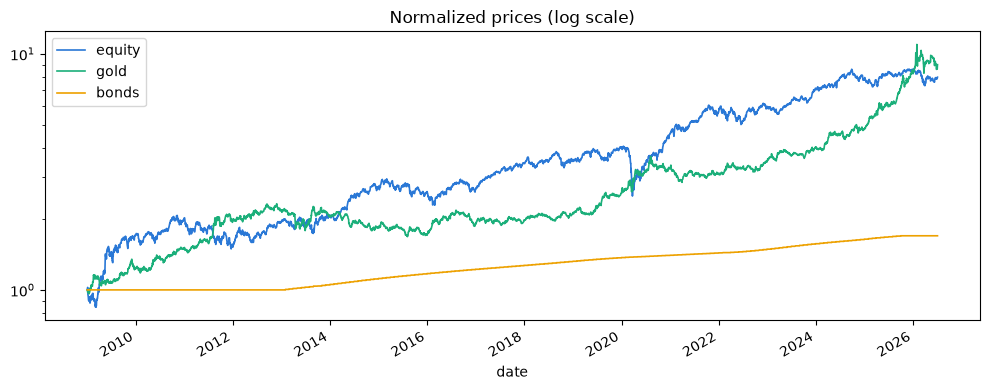

In [3]:
(prices / prices.iloc[0]).plot(figsize=(10, 4), logy=True, lw=1.2,
                               color=["#2a78d6", "#1baf7a", "#eda100"],
                               title="Normalized prices (log scale)")
plt.tight_layout()

## 2. Features

Two causal features on the equity index: daily log return and 21-day realized
volatility. Each row `t` depends only on prices up to `t`. Standardization is
split into fit/apply so it can be fitted on the training window only.

In [4]:
feats=build_features(prices["equity"])
feats.tail(3)

,log_ret,realized_vol
date,,
2026-07-01,0.005853,0.007094
2026-07-02,0.007050,0.007135
2026-07-03,0.003928,0.007149


## 3. The HMM, fitted causally — a demonstration

To show what the model learns, fit on the warmup window only (first ~5 years)
and inspect the states. Raw state indices are arbitrary, so `fit_hmm` maps them
to labels from the fitted moments: **crisis** is the highest-volatility state
(volatility clustering is the robust discriminator — "highest mean return" can
point at a violent 2009-style rebound), then **bull** is the higher-return of
the remaining two.

In [5]:
warmup=BACKTEST_CONFIG.warmup_days
fitted=fit_hmm(feats.iloc[:warmup])
print("state -> label:", fitted.state_to_label)
print("state means [scaled ret, scaled vol]:")
print(np.round(fitted.model.means_, 3))
print("transition matrix (note the heavy diagonal = regime persistence):")
print(np.round(fitted.model.transmat_, 3))

state -> label: {1: 'bull', 0: 'bear', 2: 'crisis'}
state means [scaled ret, scaled vol]:
[[-0.094 -0.33 ]
 [ 0.001 -0.896]
 [ 0.108  0.976]]
transition matrix (note the heavy diagonal = regime persistence):
[[0.969 0.014 0.018]
 [0.021 0.979 0.   ]
 [0.023 0.    0.977]]


The heavy diagonal of the transition matrix is the point of using an HMM:
states are *persistent*, so the filtered belief doesn't chase every noisy day.

Below, the **filtered** posterior around the COVID crash — computed with the
forward recursion only, i.e. exactly what an observer could have known each
day. Note this uses the model fitted on data through 2014 only, applied years
out of sample.

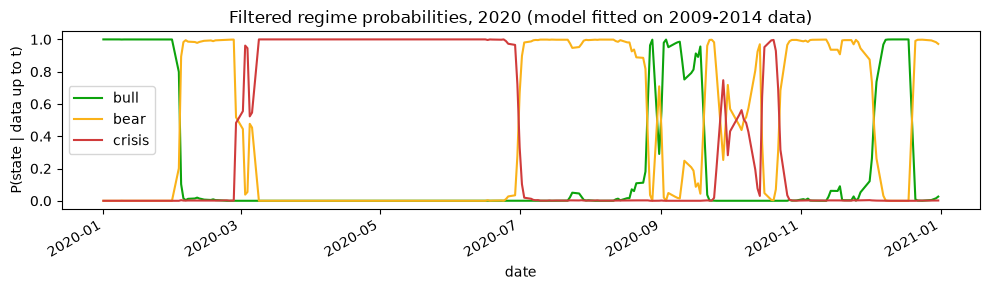

In [6]:
post=filtered_posteriors(fitted, feats)
window=post.loc["2020-01":"2020-12"]
ax=window.plot(figsize=(10, 3), lw=1.5,
               color={"bull": "#0ca30c", "bear": "#fab219", "crisis": "#d03b3b"},
               title="Filtered regime probabilities, 2020 (model fitted on 2009-2014 data)")
ax.set_ylabel("P(state | data up to t)")
plt.tight_layout()

## 4. Walk-forward backtest

The engine (`src/backtest.py`) steps through time: refits the HMM every 126
trading days on an expanding window, decodes the regime with the filtered
posterior, and rebalances monthly **and** on confident regime switches (the
acting regime only flips when the new regime's filtered probability clears
0.70, which debounces boundary flapping). The optimizer (`src/optimize.py`)
solves a long-only mean-variance problem whose risk aversion and return
shrinkage depend on the regime; in crisis it degenerates to pure minimum
variance. A 7 bps cost on turnover is charged to strategy and benchmarks alike.

Takes a few minutes (about 25 HMM refits plus a few hundred cvxpy solves).

In [7]:
strat=run_walkforward(prices)
returns=prices.pct_change().dropna()
benches=run_benchmarks(returns, strat.targets.index, BACKTEST_CONFIG.tc_bps)
print(f"{len(strat.returns)} trading days, annual turnover {strat.annual_turnover:.2f}")

INFO refit at 2014-03-13: state means (ret) [-0.075  0.128  0.007]


INFO refit at 2014-09-18: state means (ret) [-0.004  0.104 -0.085]


INFO refit at 2015-03-30: state means (ret) [-0.001 -0.084  0.108]


INFO refit at 2015-09-30: state means (ret) [ 0.003 -0.079  0.096]


INFO refit at 2016-04-07: state means (ret) [-0.076 -0.002  0.102]


INFO refit at 2016-10-13: state means (ret) [-0.003  0.099 -0.072]


... (16 outputs left out)

INFO refit at 2025-06-16: state means (ret) [-0.045  0.005  0.081]


INFO refit at 2025-12-16: state means (ret) [ 0.082 -0.044  0.004]


INFO refit at 2026-06-19: state means (ret) [ 0.006 -0.046  0.081]


3034 trading days, annual turnover 5.20


## 5. Results

The final ~20% of history is a **locked holdout** that was never consulted
while developing the model — the honest headline is the holdout table.

In [8]:
named={"RegimeShift": strat.returns, **{k: v.returns for k, v in benches.items()}}
turnover={"RegimeShift": strat.annual_turnover,
          **{k: v.annual_turnover for k, v in benches.items()}}
stats_table(named, turnover).round(3)

,CAGR,AnnVol,Sharpe,Sortino,MaxDD,Calmar,AnnTurnover
RegimeShift,0.099,0.086,1.140,1.322,-0.153,0.649,5.197
60/40,0.087,0.095,0.929,1.153,-0.241,0.363,0.241
equal_weight,0.099,0.073,1.332,1.664,-0.155,0.639,0.323


In [9]:
holdout_start=prices.index[int(len(prices) * (1 - BACKTEST_CONFIG.holdout_frac))]
print("Development period (pre", holdout_start.date(), ")")
display(stats_table({k: v[v.index < holdout_start] for k, v in named.items()}).round(3))
print("LOCKED HOLDOUT (", holdout_start.date(), "onward )")
display(stats_table({k: v[v.index >= holdout_start] for k, v in named.items()}).round(3))

Development period (pre 2023-01-04 )


,CAGR,AnnVol,Sharpe,Sortino,MaxDD,Calmar
RegimeShift,0.067,0.060,1.121,1.498,-0.080,0.838
60/40,0.095,0.102,0.940,1.149,-0.241,0.393
equal_weight,0.081,0.067,1.201,1.572,-0.155,0.522


LOCKED HOLDOUT ( 2023-01-04 onward )


,CAGR,AnnVol,Sharpe,Sortino,MaxDD,Calmar
RegimeShift,0.184,0.131,1.354,1.482,-0.153,1.201
60/40,0.070,0.077,0.917,1.260,-0.093,0.749
equal_weight,0.146,0.087,1.615,1.879,-0.127,1.148


In [10]:
regime_stats(strat.returns, strat.regimes).round(4)

,days,share,ann_ret,ann_vol
bear,878.0,0.2894,0.0322,0.0538
bull,1765.0,0.5817,0.1449,0.1041
crisis,391.0,0.1289,0.0365,0.0473


### Plots

Generated by `src/metrics.py` and saved to `results/` (same files the CLI
produces).

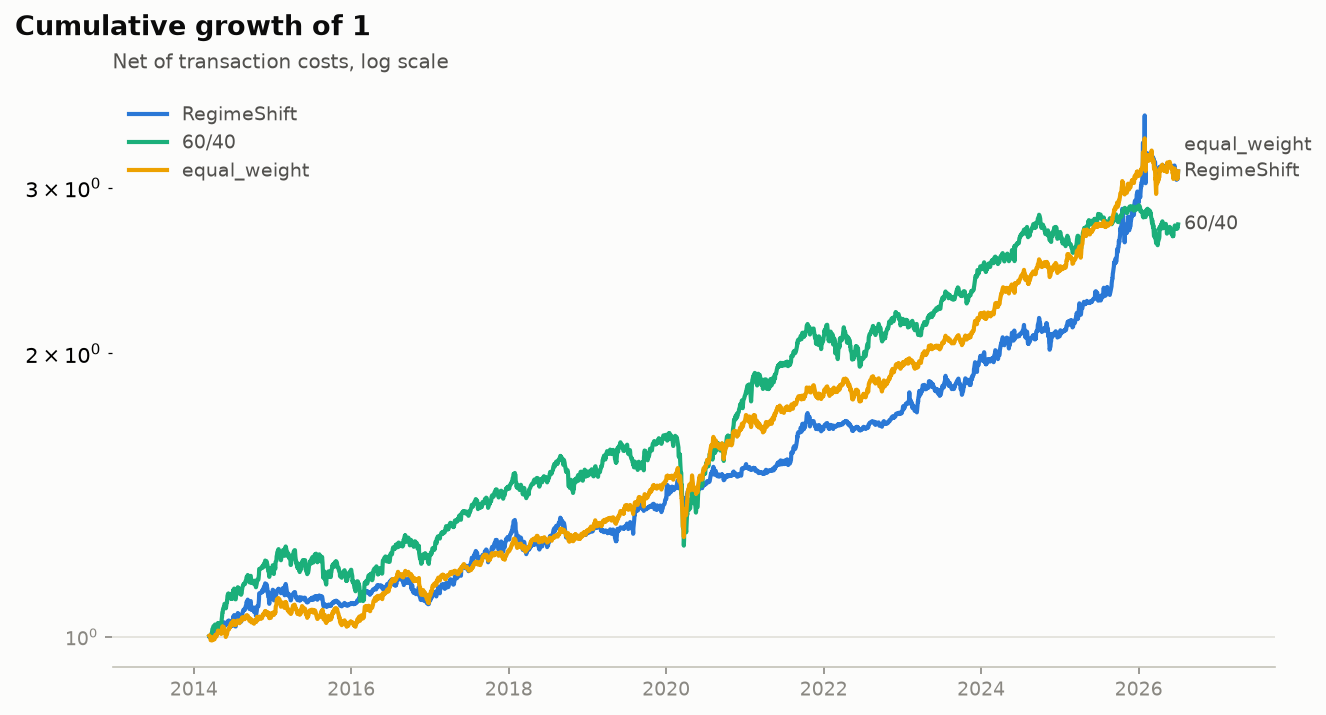

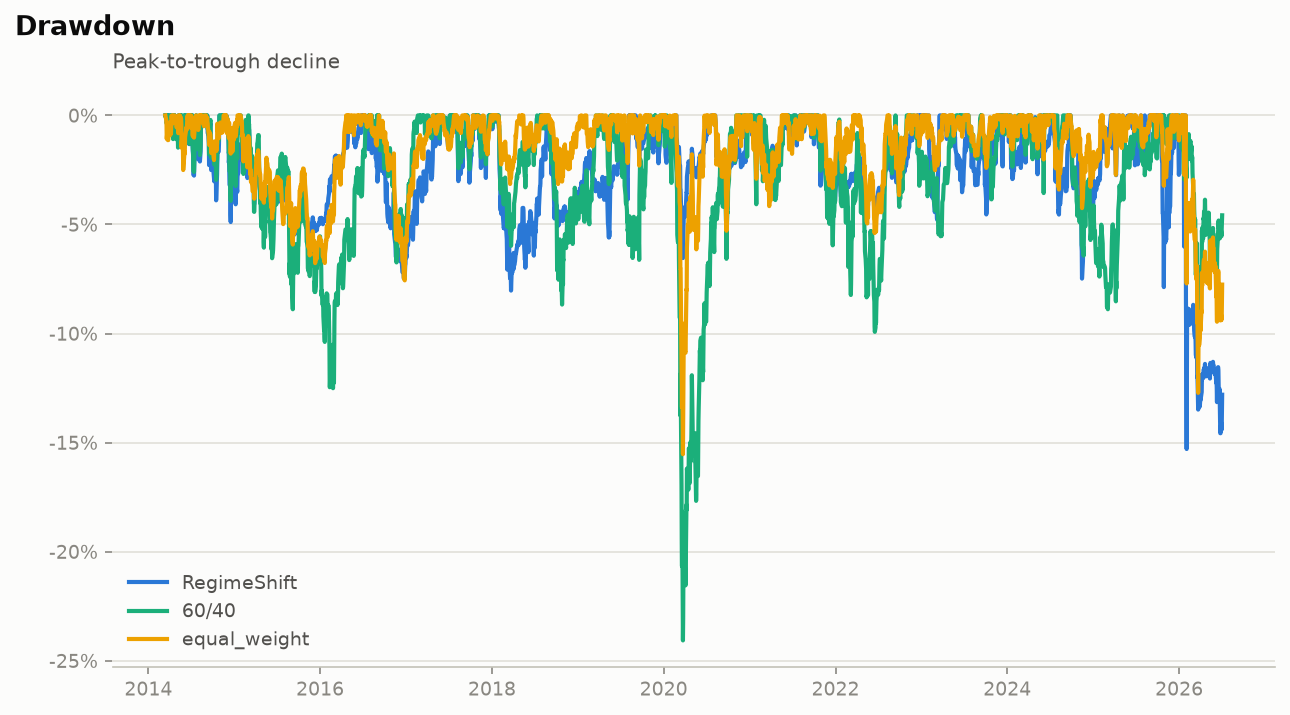

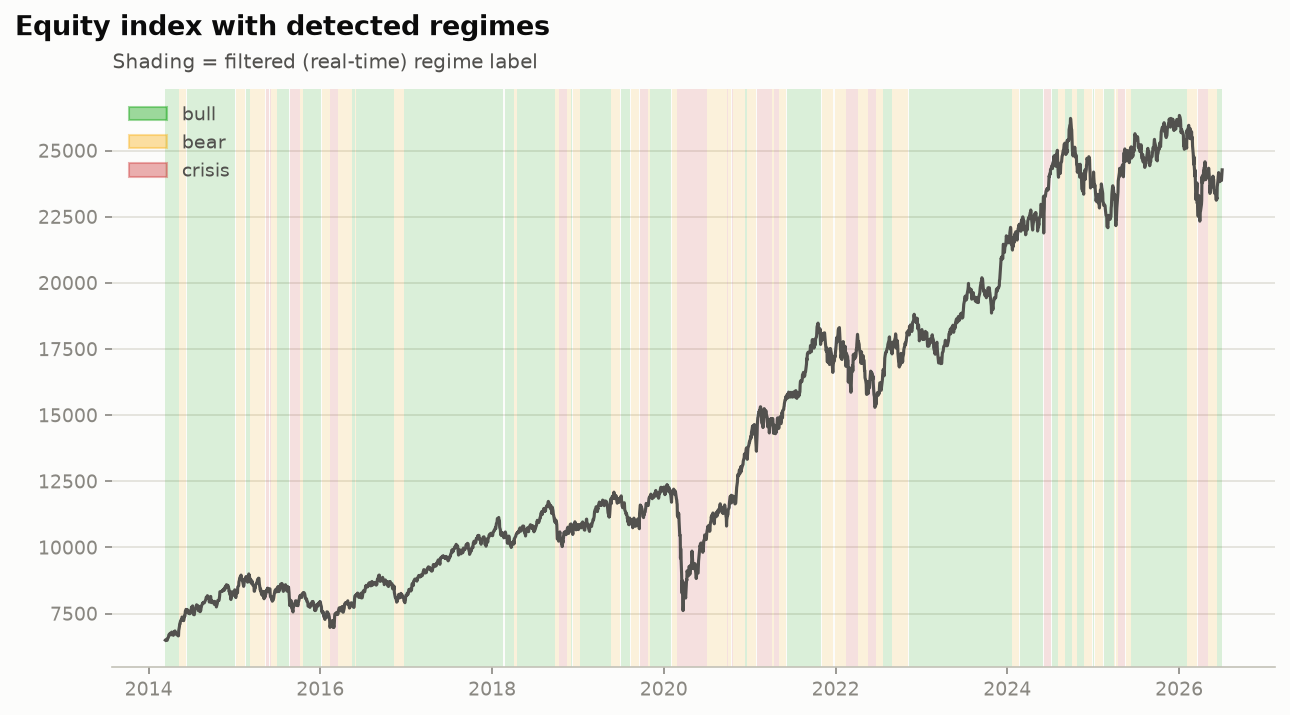

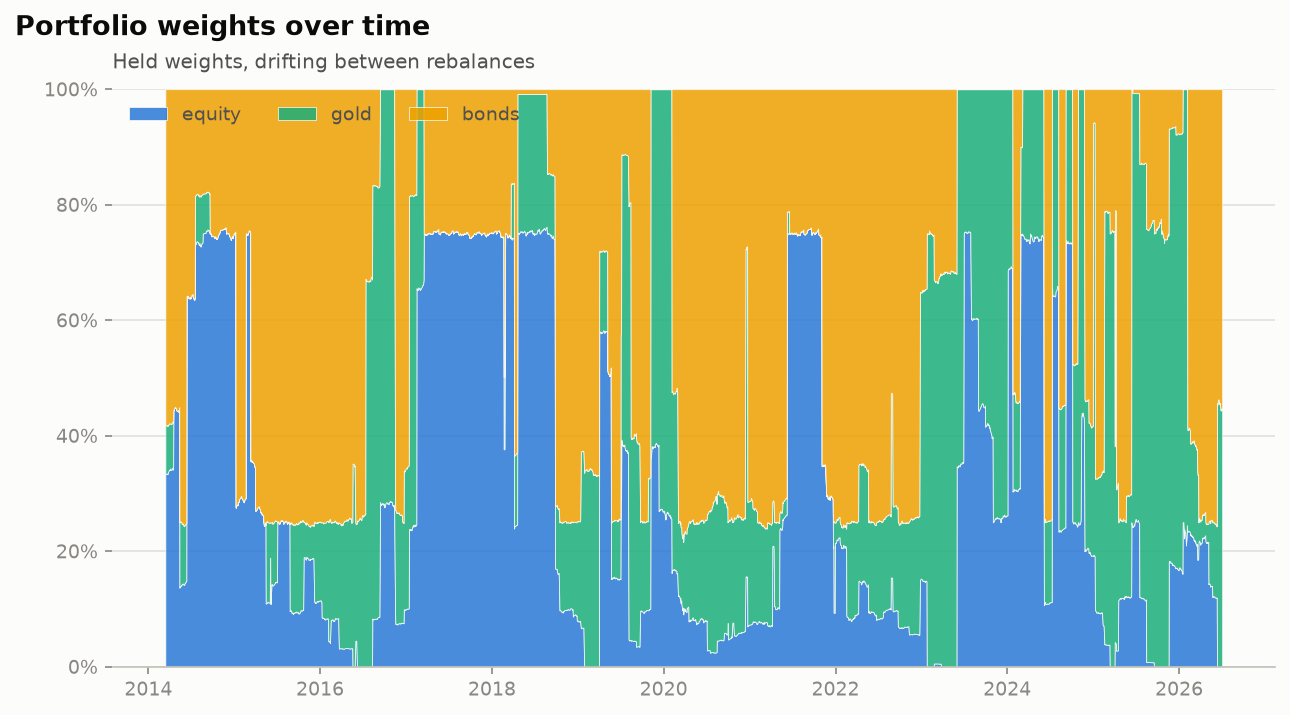

In [11]:
from IPython.display import Image, display
for p in save_all_plots(strat.returns, {k: v.returns for k, v in benches.items()},
                        prices["equity"], strat.regimes, strat.weights, RESULTS_DIR):
    display(Image(filename=p))

## 6. Honest discussion

- **What worked.** The filtered HMM cleanly identifies the 2020 crash and the
  2021-22 tightening chop; the strategy beats 60/40 on every metric over the
  full walk-forward and beats both benchmarks on CAGR and Calmar in the locked
  holdout, with the crisis sleeve cutting the worst drawdown well below 60/40's.
- **What didn't.** Equal-weight is a hard benchmark on Sharpe in this sample:
  a third of it sat in gold through one of gold's best decades in INR terms.
  The strategy pays real transaction costs for its regime responsiveness.
- **Data compromises.** The defensive leg is a cash-like liquid ETF, not a
  duration bond ETF (Yahoo history constraint), and Yahoo's dividend
  adjustments likely *understate* its true return — a conservative bias.
- **Assumptions.** Trades fill at the close on the decision day at 7 bps
  linear cost; no taxes, slippage beyond the linear cost, or borrowing.
- **Fixed by design, not tuned.** 3 states, 2 features, semi-annual refits,
  monthly cadence, 0.70 switch confidence, the regime->risk-aversion map, and
  the cost-calibrated turnover penalty were chosen on the grounds documented
  in `src/config.py` and never swept against the holdout.